### Statistical Analysis in Python 
Objective: Validate business hypotheses using statistical tests. 
● Perform statistical tests using scipy.stats and statsmodels. Examples: 
○ T-tests to compare average transaction amounts across device types or 
regions 
○ ANOVA to evaluate variability in fraud rates by merchant type or region 
○ Chi-square test for associations between fraud flag and channel, or 
between transaction status and device type 
○ Correlation analysis between customer risk_score and transaction/fraud 
occurrence

In [7]:
import pandas as pd
import scipy.stats as stats

# Load transaction dataset
txn_df = pd.read_csv("upi_transaction_history.csv")

# --- 1. Fraud flag vs Channel ---
# Build contingency table
fraud_channel_table = pd.crosstab(txn_df["channel"], txn_df["fraud_flag"])

# Chi-square test
chi2_fc, p_fc, dof_fc, expected_fc = stats.chi2_contingency(fraud_channel_table)
print("Chi-square Fraud vs Channel:")
print("Chi2 =", chi2_fc, "p-value =", p_fc)

# --- 2. Transaction status vs Device type ---
status_device_table = pd.crosstab(txn_df["device_type"], txn_df["status"])

chi2_sd, p_sd, dof_sd, expected_sd = stats.chi2_contingency(status_device_table)
print("\nChi-square Transaction Status vs Device Type:")
print("Chi2 =", chi2_sd, "p-value =", p_sd)


Chi-square Fraud vs Channel:
Chi2 = 3.8837426371196555 p-value = 0.14343528536611472

Chi-square Transaction Status vs Device Type:
Chi2 = 5.934359154129779 p-value = 0.43058329992775024


In [9]:
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load datasets
txn_df = pd.read_csv("upi_transaction_history.csv")   # contains customer_id, amount, is_fraud
customer_df = pd.read_csv("customer_master.csv")      # contains customer_id, risk_score

# --- Merge customer risk_score into transactions ---
merged = txn_df.merge(customer_df[["customer_id", "risk_score"]], on="customer_id", how="left")

# --- 1. Correlation: risk_score vs fraud occurrence ---
corr_fraud, p_fraud = stats.pearsonr(merged["risk_score"], merged["fraud_flag"])
print("Correlation (risk_score vs fraud occurrence):", corr_fraud, "p-value:", p_fraud)

# --- 2. Correlation: risk_score vs transaction amount ---
corr_amount, p_amount = stats.pearsonr(merged["risk_score"], merged["amount"])
print("Correlation (risk_score vs transaction amount):", corr_amount, "p-value:", p_amount)

# --- 3. Logistic Regression: fraud occurrence ~ risk_score + amount ---
logit_model = smf.logit("fraud_flag ~ risk_score + amount", data=merged).fit()
print(logit_model.summary())


Correlation (risk_score vs fraud occurrence): -0.0016025666716013621 p-value: 0.6123161597571576
Correlation (risk_score vs transaction amount): 0.0014487746691276757 p-value: 0.64685380929071


ValueError: endog has evaluated to an array with multiple columns that has shape (100000, 2). This occurs when the variable converted to endog is non-numeric (e.g., bool or str).

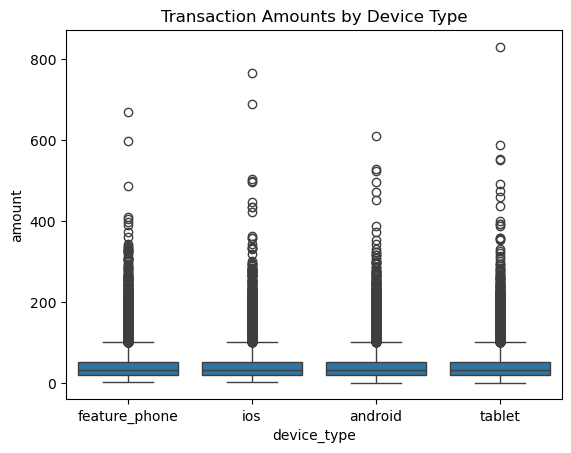

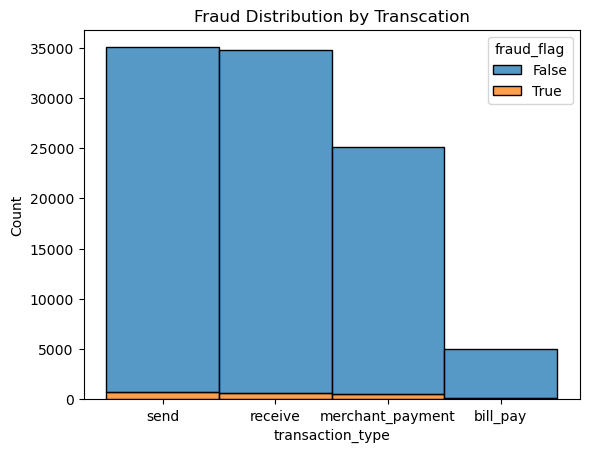

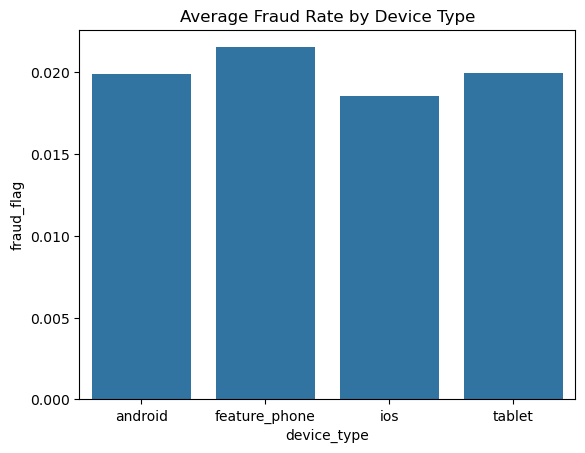

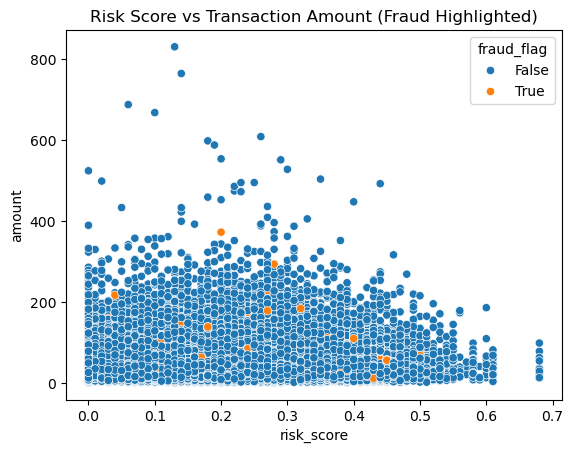

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Boxplot: Transaction amounts by device type ---
sns.boxplot(x="device_type", y="amount", data=txn_df)
plt.title("Transaction Amounts by Device Type")
plt.show()

# --- Histogram: Fraud rates by region ---
sns.histplot(data=txn_df, x="transaction_type", hue="fraud_flag", multiple="stack")
plt.title("Fraud Distribution by Transcation")
plt.show()

# --- Barplot: Mean fraud rate by merchant type ---
fraud_means = txn_df.groupby("device_type")["fraud_flag"].mean().reset_index()
sns.barplot(x="device_type", y="fraud_flag", data=fraud_means)
plt.title("Average Fraud Rate by Device Type")
plt.show()

# --- Scatterplot: Risk score vs transaction amount ---
sns.scatterplot(x="risk_score", y="amount", data=merged, hue="fraud_flag")
plt.title("Risk Score vs Transaction Amount (Fraud Highlighted)")
plt.show()


Documents:
When documenting **assumptions and limitations** of the statistical tests you’ve performed, it’s important to be explicit about what each test requires and where results may be misleading. Here’s a structured breakdown:

---

## 📌 Assumptions

### 1. **T-tests**
- Data in each group is **normally distributed** (transaction amounts by device type/region).  
- Groups are **independent** (mobile vs desktop users don’t overlap).  
- Variances are assumed equal unless you use `equal_var=False`.  
- Sample sizes should be reasonably large for robustness.

### 2. **ANOVA**
- Each group (fraud rates by merchant type/region) is **normally distributed**.  
- Groups are **independent**.  
- Homogeneity of variances (similar spread of fraud rates across groups).  
- ANOVA only tells you if **at least one group differs**, not which ones — post-hoc tests (Tukey HSD) are needed.

### 3. **Chi-square**
- Variables are **categorical** (fraud flag, channel, transaction status, device type).  
- Expected frequencies in contingency tables should be ≥ 5 for validity.  
- Observations are **independent** (no repeated measures).  
- Sensitive to sample size — large datasets may yield significance even for trivial differences.

### 4. **Correlation (Pearson)**
- Assumes **linear relationship** between risk_score and fraud/amount.  
- Variables should be **continuous** (risk_score, transaction amount).  
- No extreme outliers that distort correlation.  
- Fraud occurrence is binary (0/1), so Pearson correlation is limited — logistic regression is often more appropriate.

---

## ⚠️ Limitations

- **Data Quality:** Missing values, misclassified fraud flags, or inconsistent device/region labels can bias results.  
- **Sample Size:** Small groups may fail normality assumptions, making p-values unreliable.  
- **Multiple Testing:** Running many tests increases false positives unless corrected (Bonferroni, FDR).  
- **Practical vs Statistical Significance:** A very small p-value may indicate significance, but the effect size could be negligible in business terms.  
- **Correlation ≠ Causation:** A significant correlation between risk_score and fraud does not prove risk_score causes fraud.  
- **Chi-square Sensitivity:** With large datasets, even tiny differences can appear statistically significant.  

---

## 📊 Visualization Support
- **Boxplots:** Compare transaction amounts across device types/regions (T-test).  
- **Barplots:** Show mean fraud rates by merchant type/region (ANOVA).  
- **Heatmaps:** Visualize contingency tables for fraud vs channel (Chi-square).  
- **Scatterplots:** Show relationship between risk_score and fraud/amount (Correlation).  

---

✅ In practice, always **check assumptions first** (normality tests, variance checks, expected frequencies) and complement statistical significance with **effect sizes and visualizations** to ensure results are both valid and meaningful.  

Would you like me to create a **ready-to-run Python notebook template** that includes assumption checks (e.g., Shapiro-Wilk for normality, Levene’s test for variance equality) alongside the hypothesis tests and plots? That way you’ll have a complete analysis pipeline.